# Mecânica dos Fluidos — Projeto 1
## Escoamento de Hagen–Poiseuille: da modelagem física à solução pelo Método dos Elementos Finitos

**Prazo:** 3 semanas  
**Entrega:** artigo em PDF + notebook Jupyter (`.ipynb`) executável

### Objetivo
Estudar o escoamento laminar em um tubo cilíndrico, partindo da dedução física [Nussenzveig, 2004] e desenvolvendo a formulação variacional, a solução pelo MEF/FEniCSx e sua verificação.

$$
\boxed{\text{problema físico}\to\text{modelo}\to\text{solução analítica}\to\text{forma fraca}\to\text{MEF}\to\text{FEniCSx}\to\text{verificação}}
$$

Este notebook é um **roteiro**, não uma solução pronta. As células incompletas deverão ser desenvolvidas pelo grupo.

## 1. Referência básica

**NUSSENZVEIG, H. M.** *Curso de Física Básica: Fluidos, Oscilações e Ondas, Calor*. v. 2. 4. ed. São Paulo: Edgard Blücher, 2002. Reimpressão, 2004.

Consultar a seção sobre viscosidade, particularmente a dedução da **lei de Hagen–Poiseuille**.

O grupo deverá citar a fonte e apresentar a dedução com suas próprias explicações.

## 2. Problema físico

Considere um tubo de raio $a$ e comprimento $l$, contendo um fluido newtoniano de viscosidade $\eta$, submetido a pressões $p_1>p_2$.

Admite-se escoamento estacionário, incompressível, laminar, axisimétrico e plenamente desenvolvido:

$$v=v(r).$$

Na parede:
$$\boxed{v(a)=0}.$$

No eixo, por simetria:
$$\boxed{\left.\frac{dv}{dr}\right|_{r=0}=0}.$$

### Para pensar
1. Por que $v$ depende apenas de $r$?
2. Por que $v(a)=0$?
3. Por que não devemos impor $v(0)=0$?
4. Onde se espera a velocidade máxima?

### Respostas — "Para pensar" (Seção 2)

1. **Por que $v=v(r)$?** O escoamento é *estacionário* (sem $t$), *axisimétrico* (sem $\theta$) e *plenamente desenvolvido* (longe da entrada, o perfil não muda com $z$). Como o fluido é incompressível e o tubo é reto, só resta a componente axial, que varia apenas com a distância ao eixo.
2. **Por que $v(a)=0$?** Condição de *não deslizamento*: as moléculas de um fluido viscoso aderem à parede sólida, que está em repouso.
3. **Por que não impor $v(0)=0$?** $r=0$ não é parede, é o *eixo* — um ponto interior do fluido, onde ele escoa mais rápido. A informação correta é de simetria, $v'(0)=0$, e ela **não precisa ser imposta**: sai sozinha da forma fraca (condição natural, Seção 5).
4. **Onde está $v_{\max}$?** No eixo, $v(0)=\dfrac{Ga^2}{4\eta}$, pois $v'(r)<0$ para todo $r>0$.

## 3. Dedução física — ponto de partida

Seguindo Nussenzveig, considere um cilindro coaxial de fluido de raio $r$ e comprimento $l$.

$$F_p=(p_1-p_2)\pi r^2,$$

enquanto a área lateral é

$$A=2\pi r l.$$

Assim,

$$\frac{F}{A}=\frac{p_1-p_2}{2l}r.$$

Pela lei de Newton da viscosidade,

$$\frac{F}{A}=-\eta\frac{dv}{dr},$$

logo

$$\boxed{\frac{dv}{dr}=-\frac{p_1-p_2}{2l\eta}r}.$$

### Tarefa
Complete no artigo a integração e mostre como $v(a)=0$ conduz ao perfil parabólico.

### Integração e perfil parabólico (Seção 3)

De $\dfrac{dv}{dr}=-\dfrac{G}{2\eta}\,r$ (com $G=\frac{p_1-p_2}{l}$), integrando em $r$:

$$v(r)=-\frac{G}{4\eta}r^2+C.$$

A condição de parede $v(a)=0$ fixa $C=\dfrac{Ga^2}{4\eta}$, logo

$$\boxed{v(r)=\frac{G}{4\eta}\,(a^2-r^2)}\qquad\Rightarrow\qquad Q=\int_0^a v\,2\pi r\,dr=\frac{\pi a^4 G}{8\eta}.$$

Perfil parabólico, máximo no eixo, e $Q\propto a^4$ (Lei de Hagen–Poiseuille, Nussenzveig, 2004).

## 4. Solução analítica para verificação

Defina

$$G=\frac{p_1-p_2}{l}.$$

A solução analítica é

$$\boxed{v_{\rm exato}(r)=\frac{G}{4\eta}(a^2-r^2)}.$$

A vazão é

$$\boxed{Q_{\rm exato}=\frac{\pi a^4G}{8\eta}}.$$

A solução analítica será utilizada para **verificar** a implementação numérica.

## 5. Da equação diferencial à forma fraca

Uma forma conveniente da equação é

$$-\frac{1}{r}\frac{d}{dr}\left(\eta r\frac{dv}{dr}\right)=G.$$

Multiplicando por $r$:

$$-\frac{d}{dr}\left(\eta r\frac{dv}{dr}\right)=Gr.$$

### Tarefa de formulação
Utilize uma função teste $w$, integre por partes e obtenha

$$\boxed{\int_0^a\eta r\,v'w'\,dr=\int_0^a Gr\,w\,dr}.$$

No artigo:
1. mostre os passos;
2. discuta o termo de fronteira;
3. explique a condição de simetria em $r=0$;
4. explique a origem do fator $r$.

### Dedução da forma fraca (Seção 5)

Multiplique $-\dfrac{d}{dr}\!\left(\eta r v'\right)=Gr$ por uma função teste $w$ e integre em $[0,a]$:

$$-\int_0^a\frac{d}{dr}\!\left(\eta r v'\right)w\,dr=\int_0^a Gr\,w\,dr.$$

Integrando por partes,

$$-\Big[\eta r\,v'\,w\Big]_0^a+\int_0^a\eta r\,v'w'\,dr=\int_0^a Gr\,w\,dr.$$

**Termo de fronteira.**
- Em $r=a$: $v$ é prescrita ($v(a)=0$), então a função teste é escolhida com $w(a)=0$ e o termo some.
- Em $r=0$: aparece o fator $r$, de modo que $\eta r v' w\to0$ desde que $v'$ e $w$ sejam limitados. O termo some **sem que se imponha nada** — a condição de simetria $v'(0)=0$ é *natural* (satisfeita pela própria solução da forma fraca), ao contrário de $v(a)=0$, que é *essencial* e precisa ser imposta no espaço.

**Origem do fator $r$.** É o jacobiano da coordenada cilíndrica ($dA=2\pi r\,dr$): o Laplaciano axisimétrico é $\frac1r\frac{d}{dr}(r\,\eta\,v')$, e multiplicar por $r$ transforma o operador numa forma autoadjunta com peso $r$. Fisicamente, anéis mais externos têm mais área e pesam mais.

Resultado: $\displaystyle\int_0^a\eta r\,v'w'\,dr=\int_0^a Gr\,w\,dr$, ou seja $a(v,w)=\ell(w)$.

## 6. Ambiente computacional

Recomenda-se **VS Code + Jupyter**, no ambiente FEniCSx utilizado nas aulas.

O notebook deve ser reprodutível: depois de reiniciar o kernel, **Run All** deverá reproduzir os resultados sem depender de execuções anteriores.

In [1]:
# Importações básicas
import os
import numpy as np
import matplotlib.pyplot as plt

from mpi4py import MPI
from petsc4py import PETSc
import dolfinx
from dolfinx import mesh, fem
from dolfinx.fem.petsc import LinearProblem
import ufl

os.makedirs("figuras", exist_ok=True)      # figuras usadas no artigo
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
COR_EXATA, COR_MEF = "#1f4e79", "#d95f02"  # azul = analítica, laranja = MEF

print("Ambiente carregado. dolfinx", dolfinx.__version__)

Ambiente carregado. dolfinx 0.11.0


## 7. Parâmetros físicos

Escolha valores coerentes para $a$, $l$, $\eta$, $p_1$ e $p_2$, registre as unidades e calcule

$$G=\frac{p_1-p_2}{l}.$$

In [2]:
# Parâmetros físicos (SI) — água a ~20 °C escoando em um tubo fino
a       = 2.0e-3     # raio do tubo [m]            (diâmetro de 4 mm)
l       = 1.0        # comprimento do tubo [m]
eta_val = 1.0e-3     # viscosidade dinâmica [Pa·s] (água)
rho     = 1000.0     # massa específica [kg/m³]    (só para checar o regime)
p1      = 20.0       # pressão de entrada [Pa]     (manométrica)
p2      = 0.0        # pressão de saída [Pa]

# Gradiente de pressão (queda de pressão por unidade de comprimento) [Pa/m]
G_val = (p1 - p2) / l

# Grandezas analíticas de referência
v_max  = G_val * a**2 / (4 * eta_val)               # velocidade no eixo [m/s]
Q_exat = np.pi * a**4 * G_val / (8 * eta_val)       # vazão de Hagen–Poiseuille [m³/s]
v_med  = Q_exat / (np.pi * a**2)                    # velocidade média [m/s] (= v_max/2)

# Verificação das hipóteses: escoamento laminar e plenamente desenvolvido?
Re  = rho * v_med * (2 * a) / eta_val               # Reynolds (diâmetro como escala)
L_e = 0.05 * Re * (2 * a)                           # comprimento de entrada (estimativa clássica)

print(f"G        = {G_val:.3f} Pa/m")
print(f"v_max    = {v_max*1e3:.3f} mm/s   (v_med = {v_med*1e3:.3f} mm/s)")
print(f"Q_exato  = {Q_exat:.4e} m³/s = {Q_exat*1e6:.4f} mL/s")
print(f"Re       = {Re:.1f}  (<< ~2000: laminar)")
print(f"L_entrada ≈ {L_e*1e3:.1f} mm << l = {l*1e3:.0f} mm  (plenamente desenvolvido)")

G        = 20.000 Pa/m
v_max    = 20.000 mm/s   (v_med = 10.000 mm/s)
Q_exato  = 1.2566e-07 m³/s = 0.1257 mL/s
Re       = 40.0  (<< ~2000: laminar)
L_entrada ≈ 8.0 mm << l = 1000 mm  (plenamente desenvolvido)


## 8. Malha radial

As hipóteses reduzem o problema ao intervalo

$$0\le r\le a.$$

Crie inicialmente uma malha com poucos elementos e examine suas coordenadas.

In [3]:
# Malha radial no intervalo [0, a] com poucos elementos
N = 4
dominio = mesh.create_interval(MPI.COMM_WORLD, N, [0.0, a])

coords = dominio.geometry.x[:, 0]
print("Nº de elementos:", dominio.topology.index_map(dominio.topology.dim).size_local)
print("Coordenadas dos nós r [mm]:", np.round(np.sort(coords) * 1e3, 3))
print("Tamanho do elemento h =", a / N * 1e3, "mm")

Nº de elementos: 4
Coordenadas dos nós r [mm]: [0.  0.5 1.  1.5 2. ]
Tamanho do elemento h = 0.5 mm


## 9. Espaço de elementos finitos

Comece com elementos de Lagrange $P_1$.

Crie $V_h$, a função tentativa e a função teste.

### Para pensar
A solução parabólica de Hagen–Poiseuille pertence ao espaço $P_1$? Compare com o Couette estudado em aula.

In [4]:
# Espaço P1 de Lagrange e funções tentativa/teste
V = fem.functionspace(dominio, ("Lagrange", 1))
v = ufl.TrialFunction(V)    # incógnita v_h
w = ufl.TestFunction(V)     # função teste

print("Graus de liberdade (nós):", V.dofmap.index_map.size_global)

Graus de liberdade (nós): 5


### Resposta — "Para pensar" (Seção 9)

**A parábola pertence a $P_1$?** Não. $P_1$ contém apenas funções afins por partes, e $v(r)=C_1-C_2r^2$ tem curvatura constante. Já o escoamento de **Couette** tem perfil *linear* em $y$, que **está** em $P_1$: o MEF o reproduz exatamente com 1 elemento. Em Hagen–Poiseuille, o melhor que $P_1$ faz é aproximar a parábola por segmentos de reta (veja a Seção 14).

## 10. Coordenada radial e forma variacional

A coordenada $r$ aparece explicitamente:

$$a(v,w)=\int_0^a\eta r\,v'w'\,dr,$$

$$\ell(w)=\int_0^a Gr\,w\,dr.$$

Use `ufl.SpatialCoordinate` para representar a coordenada radial e implemente as duas formas em UFL.

In [5]:
# Coordenada radial e constantes físicas
x = ufl.SpatialCoordinate(dominio)
r = x[0]                                        # em 1D, x[0] faz o papel de r
eta = fem.Constant(dominio, PETSc.ScalarType(eta_val))
G   = fem.Constant(dominio, PETSc.ScalarType(G_val))

# Formas variacionais (o fator r aparece explicitamente):
#   a(v,w) = ∫ η r v' w' dr        ell(w) = ∫ G r w dr
a_form = eta * r * ufl.inner(ufl.grad(v), ufl.grad(w)) * ufl.dx
ell    = G * r * w * ufl.dx

## 11. Condição de contorno

Na parede,

$$v(a)=0.$$

Localize $r=a$, encontre os graus de liberdade associados e imponha a condição de Dirichlet.

Use `np.isclose` para identificar geometricamente a fronteira.

Explique por que nenhuma condição $v(0)=0$ deve ser imposta.

In [6]:
# Condição de contorno de Dirichlet na parede: v(a) = 0
fdim = dominio.topology.dim - 1                  # em 1D as "faces" são os vértices
dominio.topology.create_connectivity(fdim, dominio.topology.dim)

parede = mesh.locate_entities_boundary(dominio, fdim, lambda x: np.isclose(x[0], a))
dofs_parede = fem.locate_dofs_topological(V, fdim, parede)
bc_parede = fem.dirichletbc(PETSc.ScalarType(0.0), dofs_parede, V)

print("Vértices em r = a:", parede)
print("DOFs impostos    :", dofs_parede, "-> r =", V.tabulate_dof_coordinates()[dofs_parede, 0] * 1e3, "mm")
# Nenhuma condição é imposta em r = 0: v'(0)=0 é condição NATURAL (ver texto acima).

Vértices em r = a: [4]
DOFs impostos    : [4] -> r = [2.] mm


**Por que não impor $v(0)=0$?** Imporia que o fluido no eixo está parado — fisicamente falso (é o ponto mais rápido) e, numericamente, forçaria uma solução errada perto do eixo. A condição correta, $v'(0)=0$, é natural: o fator $r$ anula o termo de fronteira em $r=0$ na forma fraca (Seção 5), então basta *não* impor nada ali.

## 12. Solução com FEniCSx

Monte e resolva o problema.

Deixe clara no artigo a correspondência

$$\text{forma variacional}\to K\mathbf V=\mathbf f\to\text{solução numérica}.$$

In [7]:
# Montagem de K V = f e solução (LU direto)
problema = LinearProblem(
    a_form,
    ell,
    bcs=[bc_parede],
    petsc_options_prefix="hagen_poiseuille_",
    petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
)
vh = problema.solve()

# Matriz de rigidez K e vetor de carga f efetivamente montados (para o artigo)
K = problema.A
print("Dimensão de K:", K.getSize())
print("v_h nos nós [mm/s]:", np.round(vh.x.array[np.argsort(V.tabulate_dof_coordinates()[:, 0])] * 1e3, 4))

Dimensão de K: (5, 5)
v_h nos nós [mm/s]: [20.6984 19.0317 15.1429  8.8095  0.    ]


## 13. Verificação

Compare $v_h(r)$ com

$$v_{\rm exato}(r)=\frac{G}{4\eta}(a^2-r^2).$$

Apresente:
- tabela de valores;
- gráfico comparativo;
- medida quantitativa de erro.

Não se limite a afirmar que as curvas “parecem iguais”.

   r [mm]   v_h [mm/s]  v_exato [mm/s]  erro abs [mm/s]   erro rel
    0.000     20.69841        20.00000        6.984e-01   3.49e-02
    0.500     19.03175        18.75000        2.817e-01   1.50e-02
    1.000     15.14286        15.00000        1.429e-01   9.52e-03
    1.500      8.80952         8.75000        5.952e-02   6.80e-03
    2.000      0.00000         0.00000        0.000e+00        nan

Erro máximo nos nós      = 6.984e-04 m/s  (3.49e-02 de v_max)
Erro L2 (contínuo)       = 9.339e-06   (relativo: 1.430e-02)


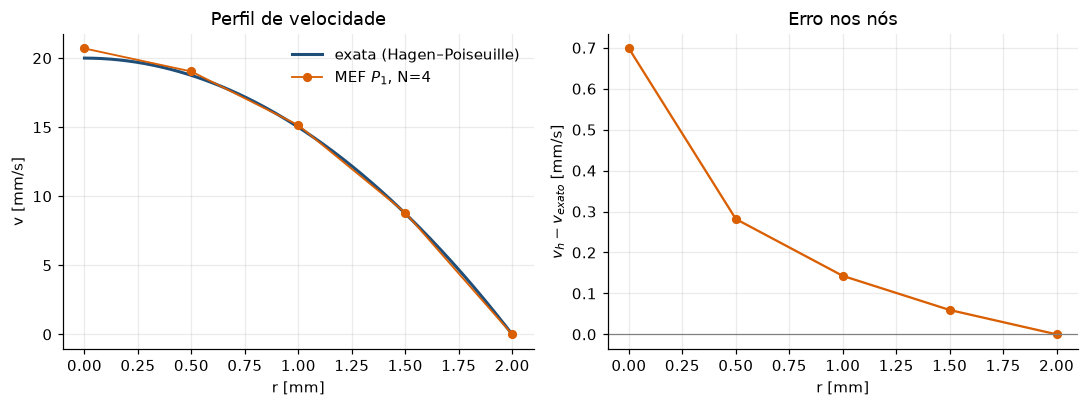

In [8]:
# Verificação: v_h  vs  v_exato(r) = G/(4 eta) (a² - r²)
def v_exato(rr):
    return G_val / (4 * eta_val) * (a**2 - rr**2)

ordem = np.argsort(V.tabulate_dof_coordinates()[:, 0])
r_nos = V.tabulate_dof_coordinates()[ordem, 0]
vh_nos = vh.x.array[ordem]
ve_nos = v_exato(r_nos)

# Erros: (i) máximo nos nós; (ii) norma L2 contínua, com a solução exata em UFL
x_ = ufl.SpatialCoordinate(dominio)
vex_ufl = G_val / (4 * eta_val) * (a**2 - x_[0]**2)
int_L2 = lambda expr: np.sqrt(dominio.comm.allreduce(fem.assemble_scalar(fem.form(expr * ufl.dx)), op=MPI.SUM))
err_L2  = int_L2((vh - vex_ufl)**2)
norm_L2 = int_L2(vex_ufl**2)
err_max_no = np.max(np.abs(vh_nos - ve_nos))

print(f"{'r [mm]':>9} {'v_h [mm/s]':>12} {'v_exato [mm/s]':>15} {'erro abs [mm/s]':>16} {'erro rel':>10}")
for rr, a1, a2 in zip(r_nos, vh_nos, ve_nos):
    rel = abs(a1 - a2) / a2 if a2 > 0 else float("nan")
    print(f"{rr*1e3:9.3f} {a1*1e3:12.5f} {a2*1e3:15.5f} {abs(a1-a2)*1e3:16.3e} {rel:10.2e}")

print(f"\nErro máximo nos nós      = {err_max_no:.3e} m/s  ({err_max_no/v_max:.2e} de v_max)")
print(f"Erro L2 (contínuo)       = {err_L2:.3e}   (relativo: {err_L2/norm_L2:.3e})")

# Gráfico comparativo
rf = np.linspace(0, a, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(rf*1e3, v_exato(rf)*1e3, color=COR_EXATA, lw=2, label="exata (Hagen–Poiseuille)")
ax1.plot(r_nos*1e3, vh_nos*1e3, "o-", color=COR_MEF, ms=5, lw=1.2, label=f"MEF $P_1$, N={N}")
ax1.set_xlabel("r [mm]"); ax1.set_ylabel("v [mm/s]"); ax1.legend(frameon=False)
ax1.set_title("Perfil de velocidade")
ax2.plot(r_nos*1e3, (vh_nos - ve_nos)*1e3, "o-", color=COR_MEF, ms=5)
ax2.axhline(0, color="gray", lw=0.8)
ax2.set_xlabel("r [mm]"); ax2.set_ylabel("$v_h - v_{exato}$ [mm/s]"); ax2.set_title("Erro nos nós")
plt.tight_layout(); plt.savefig("figuras/fig_verificacao.png", dpi=200); plt.show()

**Leitura da verificação.** Com $N=4$ elementos $P_1$, o perfil numérico é uma poligonal cujos valores nodais ficam ligeiramente **acima** da parábola (maior erro no eixo, ≈3,5 % de $v_{\max}$, e zero na parede, onde $v(a)=0$ é imposta). O erro é pequeno e quantificado (L² e máximo nodal). Observe que o erro nodal **não é nulo**: ao contrário do Couette, a solução exata não está no espaço $P_1$ (e o peso $r$ impede a "exatidão nodal" que existe para coeficientes constantes). A Seção 14 mostra como o erro cai com a malha.

## 14. Estudo de malha com $P_1$

Resolva para

$$N=2,\;4,\;8,\;16,\;32.$$

Construa uma tabela de erros e discuta:

1. há convergência?
2. como o erro varia com o refinamento?
3. por que um único $P_1$ não reproduz exatamente o perfil?
4. o que diferencia este caso do Couette?

   N    h [mm]    ||e||_L2  ordem  max erro nó  ordem
   2    1.0000   3.395e-05    nan    2.222e-03    nan
   4    0.5000   9.339e-06   1.86    6.984e-04   1.67
   8    0.2500   2.443e-06   1.93    2.106e-04   1.73
  16    0.1250   6.243e-07   1.97    6.167e-05   1.77
  32    0.0625   1.578e-07   1.98    1.767e-05   1.80


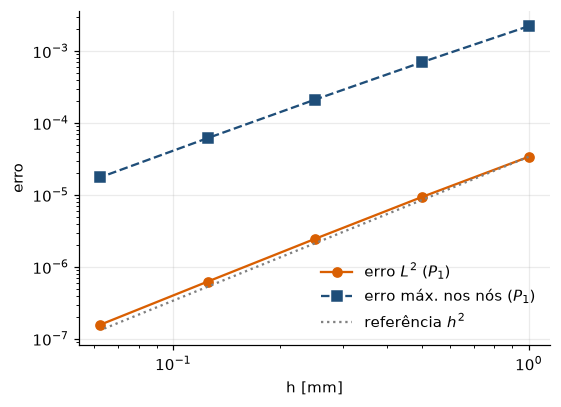

In [9]:
# Função reutilizável: resolve o problema inteiro e devolve erros e vazão
def resolver(N, grau, a, eta_val, G_val):
    """Hagen–Poiseuille 1D axisimétrico por MEF. Retorna dicionário com erros e vazão."""
    dom = mesh.create_interval(MPI.COMM_WORLD, N, [0.0, a])
    V = fem.functionspace(dom, ("Lagrange", grau))
    v, w = ufl.TrialFunction(V), ufl.TestFunction(V)
    r = ufl.SpatialCoordinate(dom)[0]
    eta = fem.Constant(dom, PETSc.ScalarType(eta_val))
    G = fem.Constant(dom, PETSc.ScalarType(G_val))

    a_form = eta * r * ufl.inner(ufl.grad(v), ufl.grad(w)) * ufl.dx
    ell = G * r * w * ufl.dx

    fdim = dom.topology.dim - 1
    dom.topology.create_connectivity(fdim, dom.topology.dim)
    ents = mesh.locate_entities_boundary(dom, fdim, lambda x: np.isclose(x[0], a))
    bc = fem.dirichletbc(PETSc.ScalarType(0.0), fem.locate_dofs_topological(V, fdim, ents), V)

    vh = LinearProblem(a_form, ell, bcs=[bc], petsc_options_prefix="hp_estudo_",
                       petsc_options={"ksp_type": "preonly", "pc_type": "lu"}).solve()

    integral = lambda expr: dom.comm.allreduce(fem.assemble_scalar(fem.form(expr * ufl.dx)), op=MPI.SUM)
    vex = G_val / (4 * eta_val) * (a**2 - r**2)
    err_L2 = np.sqrt(integral((vh - vex)**2))
    xs = V.tabulate_dof_coordinates()[:, 0]
    err_no = np.max(np.abs(vh.x.array - G_val / (4 * eta_val) * (a**2 - xs**2)))
    Q_h = 2 * np.pi * integral(vh * r)                    # Q = 2π ∫ v r dr
    Q_ex = np.pi * a**4 * G_val / (8 * eta_val)
    return dict(N=N, grau=grau, h=a / N, ndofs=V.dofmap.index_map.size_global,
                err_L2=err_L2, err_no=err_no, Q_h=Q_h, Q_ex=Q_ex,
                err_Q=abs(Q_h - Q_ex) / Q_ex)

def taxa(res, chave):
    """Ordem observada p = log(e_k / e_{k+1}) / log(h_k / h_{k+1})."""
    return [np.nan] + [np.log(res[i-1][chave] / res[i][chave]) / np.log(res[i-1]["h"] / res[i]["h"])
                       for i in range(1, len(res))]

# Estudo de malha com P1
Ns = [2, 4, 8, 16, 32]
resultados = [resolver(N, 1, a, eta_val, G_val) for N in Ns]
p_L2, p_no = taxa(resultados, "err_L2"), taxa(resultados, "err_no")

print(f"{'N':>4} {'h [mm]':>9} {'||e||_L2':>11} {'ordem':>6} {'max erro nó':>12} {'ordem':>6}")
for rs, pl, pn in zip(resultados, p_L2, p_no):
    print(f"{rs['N']:4d} {rs['h']*1e3:9.4f} {rs['err_L2']:11.3e} {pl:6.2f} {rs['err_no']:12.3e} {pn:6.2f}")

hs = np.array([rs["h"] for rs in resultados])
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.loglog(hs*1e3, [rs["err_L2"] for rs in resultados], "o-", color=COR_MEF, label="erro $L^2$ ($P_1$)")
ax.loglog(hs*1e3, [rs["err_no"] for rs in resultados], "s--", color=COR_EXATA, label="erro máx. nos nós ($P_1$)")
ax.loglog(hs*1e3, resultados[0]["err_L2"] * (hs/hs[0])**2, ":", color="gray", label="referência $h^2$")
ax.set_xlabel("h [mm]"); ax.set_ylabel("erro"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figuras/fig_convergencia_P1.png", dpi=200); plt.show()

### Discussão — estudo de malha $P_1$ (Seção 14)

1. **Há convergência?** Sim. O erro $L^2$ e o erro máximo nodal decrescem monotonicamente a cada refinamento.
2. **Como o erro varia?** A cada duplicação de $N$ o erro $L^2$ cai por um fator ≈ 4: as ordens observadas tendem a **2** (tabela acima), isto é, $\|e\|_{L^2}\sim Ch^2$, a taxa ótima de $P_1$ para soluções suaves ($h^{k+1}$ com $k=1$). O erro máximo nodal tem ordem um pouco menor (≈1,7 a 1,8 nesta faixa de $N$, crescendo com o refinamento), pois fica concentrado no eixo, onde o peso $r$ se anula.
3. **Por que um único $P_1$ não reproduz o perfil?** Porque a solução é um polinômio de grau 2 e $P_1$ só contém polinômios de grau ≤ 1 em cada elemento. O método de Galerkin devolve a *melhor aproximação em $P_1$* (na norma de energia), não a solução exata.
4. **Diferença para o Couette?** No Couette o perfil é linear, logo pertence a $P_1$ e a solução é exata para qualquer malha. Aqui, o gradiente de pressão induz curvatura (termo $-r^2$), e surge um erro de aproximação que só desaparece com $h\to0$.

## 15. Comparação $P_1\times P_2$

Repita parte do estudo com elementos de Lagrange $P_2$.

Como

$$v(r)=C_1-C_2r^2,$$

investigue:

$$\boxed{\text{qual é a relação entre a ordem da solução e a ordem do elemento finito?}}$$

Apresente evidências numéricas.

   N |  P1 erro L2  ordem |  P2 erro L2 |  P3 erro L2
   2 |   3.395e-05    nan |   1.162e-19 |   2.588e-18
   4 |   9.339e-06   1.86 |   2.041e-19 |   4.849e-18
   8 |   2.443e-06   1.93 |   9.597e-19 |   3.098e-18
  16 |   6.243e-07   1.97 |   1.042e-17 |   3.814e-18
  32 |   1.578e-07   1.98 |   1.689e-17 |   3.101e-18

Epsilon de máquina ≈ 2.220446049250313e-16  | escala de v_max = 2.00e-02 m/s
Graus de liberdade (N=8): {1: 9, 2: 17, 3: 25}


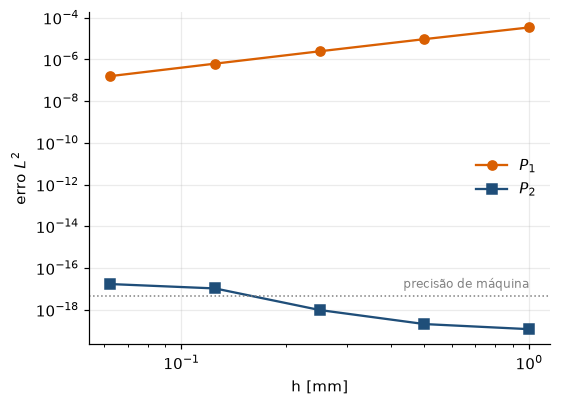

In [10]:
# Comparação P1 x P2 (e P3, como evidência adicional)
todos = {g: [resolver(N, g, a, eta_val, G_val) for N in Ns] for g in (1, 2, 3)}

print(f"{'N':>4} | {'P1 erro L2':>11} {'ordem':>6} | {'P2 erro L2':>11} | {'P3 erro L2':>11}")
for i, N in enumerate(Ns):
    print(f"{N:4d} | {todos[1][i]['err_L2']:11.3e} {taxa(todos[1], 'err_L2')[i]:6.2f} | "
          f"{todos[2][i]['err_L2']:11.3e} | {todos[3][i]['err_L2']:11.3e}")
print("\nEpsilon de máquina ≈", np.finfo(float).eps, " | escala de v_max =", f"{v_max:.2e}", "m/s")
print("Graus de liberdade (N=8):", {g: todos[g][2]['ndofs'] for g in todos})

fig, ax = plt.subplots(figsize=(5.2, 3.8))
for g, cor, mk in ((1, COR_MEF, "o"), (2, COR_EXATA, "s")):
    ax.loglog(hs*1e3, [max(rs["err_L2"], 1e-20) for rs in todos[g]], mk + "-", color=cor, label=f"$P_{g}$")
ax.axhline(np.finfo(float).eps * v_max, color="gray", ls=":", lw=1)
ax.text(hs[0]*1e3, np.finfo(float).eps * v_max * 2.5, "precisão de máquina", color="gray", fontsize=8, ha="right")
ax.set_xlabel("h [mm]"); ax.set_ylabel("erro $L^2$"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figuras/fig_P1_vs_P2.png", dpi=200); plt.show()

### Discussão — $P_1\times P_2$ (Seção 15)

**Relação entre a ordem da solução e a do elemento.** Como $v(r)=C_1-C_2r^2$ é um polinômio de **grau 2**:

- com $P_2$ (e $P_3$), a solução exata **pertence ao espaço discreto**. Como Galerkin fornece a melhor aproximação em $V_h$ na norma de energia, a solução discreta *coincide* com a exata: o erro observado é da ordem do arredondamento ($\sim10^{-17}$–$10^{-19}$), **independente da malha** (as oscilações nessa faixa são ruído numérico, não convergência);
- com $P_1$ (grau menor que o da solução), o erro decai como $h^{2}$.

Regra: *se a solução exata é polinomial de grau $m$ e o elemento é $P_k$ com $k\ge m$, o MEF a reproduz exatamente (a menos do arredondamento); se $k<m$, há erro de aproximação $O(h^{k+1})$ em $L^2$.* Além disso, com só 2 elementos $P_2$ (5 DOFs) obtém-se precisão de máquina, enquanto $P_1$ com 32 elementos (33 DOFs) ainda tem erro de ordem $10^{-7}$.

## 16. Vazão numérica

Como

$$dA=2\pi r\,dr,$$

calcule

$$\boxed{Q_h=2\pi\int_0^a v_h(r)r\,dr}$$

e compare com

$$Q_{\rm exato}=\frac{\pi a^4G}{8\eta}.$$

Apresente $Q_h$, $Q_{\rm exato}$ e o erro relativo para diferentes malhas. Explique a origem geométrica do fator $2\pi r$.

In [11]:
# Vazão numérica Q_h = 2π ∫ v_h r dr  versus  Q_exato = π a⁴ G / (8 η)
print(f"Q_exato = {Q_exat:.6e} m³/s\n")
print(f"{'N':>4} | {'Q_h (P1) [m³/s]':>16} {'erro rel':>10} {'ordem':>6} | {'Q_h (P2) [m³/s]':>16} {'erro rel':>10}")
p_Q = taxa(todos[1], "err_Q")
for i, N in enumerate(Ns):
    r1, r2 = todos[1][i], todos[2][i]
    print(f"{N:4d} | {r1['Q_h']:16.6e} {r1['err_Q']:10.2e} {p_Q[i]:6.2f} | {r2['Q_h']:16.6e} {r2['err_Q']:10.2e}")

Q_exato = 1.256637e-07 m³/s

   N |  Q_h (P1) [m³/s]   erro rel  ordem |  Q_h (P2) [m³/s]   erro rel
   2 |     1.210095e-07   3.70e-02    nan |     1.256637e-07   0.00e+00
   4 |     1.244004e-07   1.01e-02   1.88 |     1.256637e-07   0.00e+00
   8 |     1.253399e-07   2.58e-03   1.96 |     1.256637e-07   1.26e-15
  16 |     1.255821e-07   6.49e-04   1.99 |     1.256637e-07   1.58e-14
  32 |     1.256433e-07   1.63e-04   2.00 |     1.256637e-07   1.81e-14


### Discussão — vazão (Seção 16)

**Origem geométrica de $2\pi r$.** A seção do tubo é decomposta em anéis finos de raio $r$ e espessura $dr$. Cada anel tem área $dA=2\pi r\,dr$ (perímetro $2\pi r$ vezes a espessura) e, como $v$ é constante sobre o anel, contribui com $dQ=v(r)\,2\pi r\,dr$. A vazão é a soma (integral) dessas contribuições — o mesmo fator $r$ da forma fraca.

**Resultado.** Com $P_1$ o erro relativo de $Q_h$ cai com ordem ≈ 2 em $h$ (de ~3,7 % com $N=2$ para ~0,016 % com $N=32$); com $P_2$ a vazão coincide com $Q_{\rm exato}=\pi a^4G/(8\eta)$ até o arredondamento. Observação: com $P_1$ a vazão é **subestimada** em todas as malhas testadas (Q_h < Q_exato), apesar de os valores nodais próximos ao eixo ficarem acima da exata: o que conta é a integral ponderada por $r$ sobre todo o raio.

## 17. Investigação física

Investigue numericamente

$$Q\propto(p_1-p_2),\qquad Q\propto\frac1\eta,\qquad Q\propto a^4.$$

### Experimento obrigatório
Aumente o raio em **10%**, mantendo os demais parâmetros constantes.

Antes de executar:
1. faça a previsão teórica da variação percentual de $Q$;
2. execute o experimento;
3. compare teoria e resultado numérico;
4. explique o resultado.

Previsão teórica: Q cresce 46.41%  (1,10⁴ = 1.4641)

 elemento   N |   Q(a) [m³/s]  Q(1,1a) [m³/s]  variação
       P1   8 |   1.25340e-07     1.83510e-07   46.410%
       P1  32 |   1.25643e-07     1.83954e-07   46.410%
       P2   8 |   1.25664e-07     1.83984e-07   46.410%


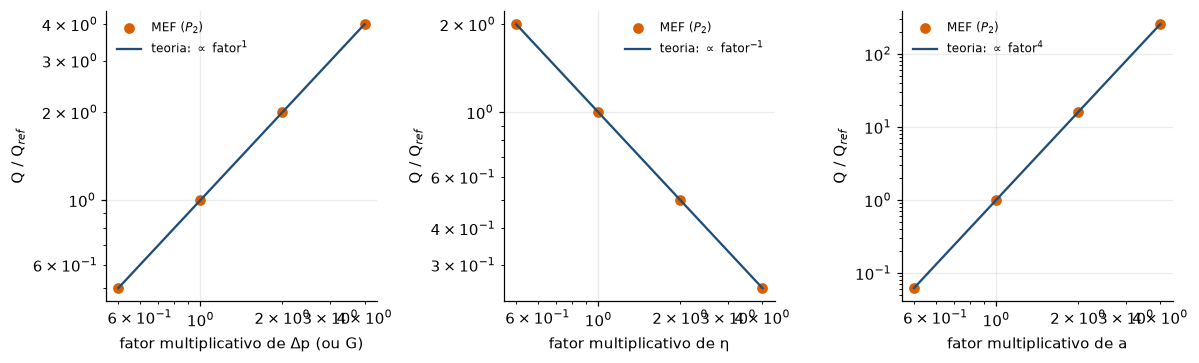

expoente numérico de Q em Δp (ou G): +1.000000   (teoria: +1)
expoente numérico de Q em         η: -1.000000   (teoria: -1)
expoente numérico de Q em         a: +4.000000   (teoria: +4)


In [12]:
# Experimento obrigatório: aumentar o raio em 10%, demais parâmetros constantes
# --- 1) Previsão teórica, ANTES de executar: Q ∝ a⁴ ---
fator_a = 1.10
previsao = fator_a**4 - 1
print(f"Previsão teórica: Q cresce {previsao*100:.2f}%  (1,10⁴ = {fator_a**4:.4f})\n")

# --- 2) Experimento numérico (P1 refinado e P2) ---
a_novo = fator_a * a
print(f"{'elemento':>9} {'N':>3} | {'Q(a) [m³/s]':>13} {'Q(1,1a) [m³/s]':>15} {'variação':>9}")
for grau, N in ((1, 8), (1, 32), (2, 8)):
    Q0 = resolver(N, grau, a, eta_val, G_val)["Q_h"]
    Q1 = resolver(N, grau, a_novo, eta_val, G_val)["Q_h"]
    print(f"{'P'+str(grau):>9} {N:3d} | {Q0:13.5e} {Q1:15.5e} {(Q1/Q0-1)*100:8.3f}%")

# --- 3) Proporcionalidades: Q ∝ Δp, Q ∝ 1/η, Q ∝ a⁴ (expoente = inclinação em log–log) ---
fatores = np.array([0.5, 1.0, 2.0, 4.0])
Q_dp  = [resolver(8, 2, a, eta_val, f * G_val)["Q_h"] for f in fatores]        # G ∝ Δp (l fixo)
Q_eta = [resolver(8, 2, a, f * eta_val, G_val)["Q_h"] for f in fatores]
Q_a   = [resolver(8, 2, f * a, eta_val, G_val)["Q_h"] for f in fatores]

expoentes = {}
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, nome, Qs, esperado in zip(axs, ["Δp (ou G)", "η", "a"], [Q_dp, Q_eta, Q_a], [1, -1, 4]):
    p = np.polyfit(np.log(fatores), np.log(Qs), 1)[0]
    expoentes[nome] = p
    ax.loglog(fatores, np.array(Qs) / Qs[1], "o", color=COR_MEF, label="MEF ($P_2$)")
    ax.loglog(fatores, fatores**esperado, "-", color=COR_EXATA, lw=1.5, label=f"teoria: $\\propto$ fator$^{{{esperado}}}$")
    ax.set_xlabel(f"fator multiplicativo de {nome}"); ax.set_ylabel("Q / Q$_{ref}$"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("figuras/fig_escalas_Q.png", dpi=200); plt.show()
for nome, esp in zip(expoentes, [1, -1, 4]):
    print(f"expoente numérico de Q em {nome:>9}: {expoentes[nome]:+.6f}   (teoria: {esp:+d})")

### Discussão — investigação física (Seção 17)

- **Previsão × resultado.** Pela lei $Q\propto a^4$, um aumento de 10 % no raio prevê $1{,}1^4-1=46{,}41\,\%$ de aumento na vazão. O experimento numérico (P2, e P1 refinado) reproduz esse valor. O resultado vale até para $P_1$ grosseiro, porque o erro relativo de discretização depende só de $N$, não de $a$ (a malha em $[0,a]$ é semelhante nos dois casos).
- **Explicação física.** O raio entra duas vezes de formas distintas: (i) a área da seção cresce com $a^2$; (ii) a velocidade típica também cresce com $a^2$ (o fluido fica mais longe da parede, onde a viscosidade o freia). Juntos: $Q\sim a^2\cdot a^2=a^4$. Uma pequena variação do raio tem, portanto, efeito amplificado (ex.: em vasos sanguíneos, uma redução de 10 % no raio diminui a vazão em ≈34 % ($0{,}9^4=0{,}656$) para o mesmo $\Delta p$).
- **Outras proporcionalidades.** Os expoentes ajustados em escala log–log são $+1$ para $\Delta p$, $-1$ para $\eta$ e $+4$ para $a$ — coincidindo com a teoria (concordância até a sexta casa decimal impressa).

## 18. Artigo — formato SBC

O relatório do Projeto 1 deverá ser escrito no formato de **artigo**, utilizando o:

**SBC Conferences Template — updated `sbc-template.sty` v2017**

Template no Overleaf:  
https://www.overleaf.com/latex/templates/sbc-conferences-template/blbxwjwzdngr

A edição pode ser feita diretamente no **Overleaf** ou em outro ambiente LaTeX compatível. A entrega final do artigo deverá ser em **PDF**.

### Estrutura sugerida

1. **Título**
2. **Autores e identificação institucional**
3. **Resumo e Abstract**
4. **Introdução**
5. **Escoamento de Hagen–Poiseuille**
   - modelo físico;
   - hipóteses;
   - solução analítica.
6. **Formulação pelo Método dos Elementos Finitos**
   - forma forte;
   - forma fraca;
   - discretização.
7. **Implementação no FEniCSx**
8. **Resultados e Discussão**
   - verificação com a solução analítica;
   - estudo de convergência da malha;
   - comparação entre $P_1$ e $P_2$;
   - cálculo da vazão;
   - investigação dos parâmetros físicos.
9. **Conclusões**
10. **Referências bibliográficas**

### Extensão

O artigo deverá ter **6 a 8 páginas**, incluindo figuras, tabelas e referências.

O **código completo não deverá ser colocado no artigo**. Trechos curtos podem ser utilizados quando forem importantes para a discussão. A implementação completa será entregue separadamente no notebook Jupyter.

O artigo deve comunicar os resultados científicos; o notebook deve garantir a **reprodutibilidade computacional**.

## 19. Conclusões

As conclusões deverão discutir, com base nos resultados:

- adequação do MEF ao problema;
- efeito do refinamento da malha;
- diferenças entre $P_1$ e $P_2$;
- concordância da vazão numérica com Hagen–Poiseuille;
- efeito dos parâmetros físicos;
- principais dificuldades encontradas.

Evite conclusões genéricas como “o objetivo foi alcançado”.

## 20. Entrega e reprodutibilidade

Cada grupo deverá entregar:

1. **artigo em PDF**, produzido com o template SBC indicado na Seção 18;
2. **notebook Jupyter (`.ipynb`) executável**.

O notebook deverá:
- executar da primeira à última célula;
- conter todos os parâmetros necessários;
- reproduzir as tabelas e figuras utilizadas no artigo;
- apresentar comentários suficientes para relacionar código e formulação matemática;
- não depender de variáveis criadas por execução fora de ordem.

### Antes de entregar

**Reinicie o kernel e execute `Run All`.**

Se o notebook não reproduzir os resultados após esse procedimento, ele não está computacionalmente reprodutível.

## 21. Organização sugerida — 3 semanas

### Semana 1 — Modelagem e formulação
Dedução física, forma forte, forma fraca e condições de contorno.

### Semana 2 — Implementação e verificação
FEniCSx, comparação analítica, estudo inicial de malha e vazão.

### Semana 3 — Experimentos e artigo
$P_1/P_2$, parâmetros físicos, gráficos, tabelas, discussão, redação e revisão.

## Uso de Inteligência Artificial

Ferramentas de Inteligência Artificial podem ser utilizadas como **apoio ao processo de aprendizagem e desenvolvimento do projeto**, por exemplo, para:

- esclarecer conceitos e comandos;
- auxiliar na identificação e interpretação de erros de programação;
- sugerir formas de organizar ou revisar um texto;
- discutir alternativas de implementação;
- auxiliar na exploração de resultados.

Entretanto, o grupo é responsável por **compreender, verificar e validar** todo o conteúdo apresentado no artigo e no notebook. Uma resposta produzida por IA não deve ser tratada como fonte de autoridade nem substituir a análise do grupo.

### Verificação crítica obrigatória

Durante o desenvolvimento do projeto, o grupo deverá selecionar **pelo menos uma interação relevante com uma ferramenta de IA** e analisá-la criticamente.

No artigo, descreva brevemente:

1. qual pergunta ou problema foi apresentado à IA;
2. qual foi a orientação ou solução proposta;
3. como o grupo verificou essa resposta;
4. se a resposta estava correta, parcialmente correta ou precisou ser modificada;
5. o que essa verificação acrescentou à compreensão do problema.

Não é necessário reproduzir longas conversas ou transcrever integralmente prompts e respostas. O objetivo é mostrar **uso consciente, verificável e tecnicamente responsável da IA**.

> **Princípio:** a IA pode auxiliar o trabalho, mas a responsabilidade pela formulação matemática, pelo código, pelos resultados e pelas conclusões permanece com o grupo.